## Notebook to analyse the results robot drive experiments


5 drives with different parameters
- drive 1: `D25.0` PWM motor speed
- drive 2: `D50.0` PWM motor speed
- drive 3: `D75.0` PWM motor speed
- drive 4: `D100.0` PWM motor speed

- drive 5: `d25.0` and `d-25.0` PWM motor speed (opposite direction, on spot turn, not main experiment)

files in
```
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.03.30-25per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.06.16-50per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.09.11-75per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.14.01-100per.txt
RTP-T3-SoSe2026\02_Preperations\recorded-data\Log_30.04.2026_09.15.49-pm25per.txt
```



In [1]:
import pathlib as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import cumulative_trapezoid

DATA_DIR = pl.Path("recorded-data")

paths = {
    "D25":   DATA_DIR / "Log_30.04.2026_09.03.30-25per.txt",
    "D50":   DATA_DIR / "Log_30.04.2026_09.06.16-50per.txt",
    "D75":   DATA_DIR / "Log_30.04.2026_09.09.11-75per.txt",
    "D100":  DATA_DIR / "Log_30.04.2026_09.14.01-100per.txt",
    "pmD25": DATA_DIR / "Log_30.04.2026_09.15.49-pm25per.txt",
}

FSAMPLE_HZ = 500  # from the `fsample=500Hz` header line


def load_log(path: pl.Path) -> pd.DataFrame:
    """Read a Serial.ICE log file (semicolon-separated, first line `fsample=...`)."""
    df = pd.read_csv(path, sep=";", skiprows=1, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    df["t/s"] = df["Time/ms"] / 1000.0
    return df


def plot_raw(df: pd.DataFrame, title: str):
    """Four-panel raw-data plot: QEI1, QEI2, distance, motor PWM vs time."""
    fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(df["t/s"], df["QEI1/steps"], color="tab:blue")
    axes[0].set_ylabel("QEI1 / steps")
    axes[1].plot(df["t/s"], df["QEI2/steps"], color="tab:orange")
    axes[1].set_ylabel("QEI2 / steps")
    axes[2].plot(df["t/s"], df["d/cm"], color="tab:green")
    axes[2].set_ylabel("distance / cm")
    mot_cols = [c for c in df.columns if c.startswith("Mot")]
    for col in mot_cols:
        axes[3].plot(df["t/s"], df[col], label=col)
    axes[3].set_ylabel("PWM / %")
    axes[3].set_xlabel("time / s")
    if len(mot_cols) > 1:
        axes[3].legend(loc="best")
    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.suptitle(title)
    fig.tight_layout()
    return fig, axes


def plot_motor_compare(df: pd.DataFrame, title: str):
    """Per-drive comparison: QEI1 and QEI2 overlaid, with their difference below."""
    fig, axes = plt.subplots(
        2, 1, figsize=(10, 6), sharex=True,
        gridspec_kw={"height_ratios": [3, 1]},
    )
    axes[0].plot(df["t/s"], df["QEI1/steps"], label="motor 0 (QEI1)", color="tab:blue")
    axes[0].plot(df["t/s"], df["QEI2/steps"], label="motor 1 (QEI2)", color="tab:orange")
    axes[0].set_ylabel("QEI position / steps")
    axes[0].legend(loc="lower right")
    axes[0].set_title(title)

    diff = df["QEI2/steps"] - df["QEI1/steps"]
    axes[1].plot(df["t/s"], diff, color="tab:red")
    axes[1].axhline(0, color="black", linewidth=0.5)
    axes[1].set_ylabel("QEI2 - QEI1\n/ steps")
    axes[1].set_xlabel("time / s")

    for ax in axes:
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, axes


def print_first_step_delay(df: pd.DataFrame, label: str = "") -> None:
    """Latency between the first non-zero motor command and the first QEI step.

    For each Mot* column, find when it first goes non-zero (= the moment the
    constant-PWM step is applied), then report when QEI1 and QEI2 each register
    their first count.
    """
    mot_cols = [c for c in df.columns if c.startswith("Mot")]
    head = f"[{label}] " if label else ""
    if not mot_cols:
        print(f"{head}no Mot* column in log")
        return
    mot = df[mot_cols[0]]
    nonzero = mot.values != 0
    if not nonzero.any():
        print(f"{head}{mot_cols[0]} stays 0 for the whole log")
        return
    cmd_pos = int(nonzero.argmax())
    t_cmd = float(df["Time/ms"].iloc[cmd_pos])
    val_cmd = float(mot.iloc[cmd_pos])
    print(f"{head}{mot_cols[0]} first reaches {val_cmd:g} % at t = {t_cmd:.0f} ms")
    for qei in ("QEI1/steps", "QEI2/steps"):
        if qei not in df.columns:
            continue
        qs = df[qei].values != 0
        if not qs.any():
            print(f"  {qei}: no step recorded")
            continue
        t_first = float(df["Time/ms"].iloc[int(qs.argmax())])
        print(f"  {qei}: first step at t = {t_first:.0f} ms  (Δt = {t_first - t_cmd:+.0f} ms)")


# ----- Smoothed time derivatives + integrals (Savitzky–Golay + trapezoidal) ---

def _savgol_deriv(qei: pd.Series, t_s: pd.Series, deriv: int,
                  window: int, polyorder: int) -> pd.Series:
    """Generic smoothed derivative via Savitzky–Golay."""
    if window % 2 == 0:
        window += 1
    fs = 1.0 / float(np.median(np.diff(t_s.values)))
    return pd.Series(
        savgol_filter(qei.values, window_length=window,
                      polyorder=polyorder, deriv=deriv, delta=1.0 / fs),
        index=qei.index,
    )


def angular_velocity(qei, t_s, window: int = 41, polyorder: int = 3) -> pd.Series:
    """Smoothed first derivative dθ/dt in steps·s⁻¹ (default window ≈ 82 ms @ 500 Hz)."""
    return _savgol_deriv(qei, t_s, deriv=1, window=window, polyorder=polyorder)


def angular_acceleration(qei, t_s, window: int = 51, polyorder: int = 4) -> pd.Series:
    """Smoothed second derivative d²θ/dt² in steps·s⁻² (default window ≈ 102 ms)."""
    return _savgol_deriv(qei, t_s, deriv=2, window=window, polyorder=polyorder)


def angular_jerk(qei, t_s, window: int = 71, polyorder: int = 5) -> pd.Series:
    """Smoothed third derivative d³θ/dt³ in steps·s⁻³ (default window ≈ 142 ms)."""
    return _savgol_deriv(qei, t_s, deriv=3, window=window, polyorder=polyorder)


def absement(qei, t_s) -> pd.Series:
    """Absement = ∫₀ᵗ θ dτ via trapezoidal cumulative integration. Units: steps·s."""
    return pd.Series(
        cumulative_trapezoid(qei.values, t_s.values, initial=0.0),
        index=qei.index,
    )


# ----- Per-drive overlay plots (motor 0 vs motor 1) ---------------------------

def plot_velocity(df, title, window: int = 41, polyorder: int = 3):
    """Both motors' smoothed angular velocity overlaid in one plot."""
    omega1 = angular_velocity(df["QEI1/steps"], df["t/s"], window, polyorder)
    omega2 = angular_velocity(df["QEI2/steps"], df["t/s"], window, polyorder)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(df["t/s"], omega1, label="motor 0 (dQEI1/dt)", color="tab:blue")
    ax.plot(df["t/s"], omega2, label="motor 1 (dQEI2/dt)", color="tab:orange")
    ax.set_xlabel("time / s")
    ax.set_ylabel(r"angular velocity / steps$\cdot$s$^{-1}$")
    ax.set_title(title)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax


def plot_acceleration(df, title, window: int = 51, polyorder: int = 4):
    """Both motors' smoothed angular acceleration overlaid in one plot."""
    a1 = angular_acceleration(df["QEI1/steps"], df["t/s"], window, polyorder)
    a2 = angular_acceleration(df["QEI2/steps"], df["t/s"], window, polyorder)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(df["t/s"], a1, label=r"motor 0 (d²QEI1/dt²)", color="tab:blue")
    ax.plot(df["t/s"], a2, label=r"motor 1 (d²QEI2/dt²)", color="tab:orange")
    ax.axhline(0, color="black", linewidth=0.5, alpha=0.5)
    ax.set_xlabel("time / s")
    ax.set_ylabel(r"angular acceleration / steps$\cdot$s$^{-2}$")
    ax.set_title(title)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax


def plot_jerk(df, title, window: int = 71, polyorder: int = 5):
    """Both motors' smoothed angular jerk overlaid in one plot."""
    j1 = angular_jerk(df["QEI1/steps"], df["t/s"], window, polyorder)
    j2 = angular_jerk(df["QEI2/steps"], df["t/s"], window, polyorder)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(df["t/s"], j1, label=r"motor 0 (d³QEI1/dt³)", color="tab:blue")
    ax.plot(df["t/s"], j2, label=r"motor 1 (d³QEI2/dt³)", color="tab:orange")
    ax.axhline(0, color="black", linewidth=0.5, alpha=0.5)
    ax.set_xlabel("time / s")
    ax.set_ylabel(r"jerk / steps$\cdot$s$^{-3}$")
    ax.set_title(title)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax


def plot_absement(df, title):
    """Both motors' absement (∫θ dt) overlaid in one plot."""
    A1 = absement(df["QEI1/steps"], df["t/s"])
    A2 = absement(df["QEI2/steps"], df["t/s"])
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(df["t/s"], A1, label=r"motor 0 ($\int$QEI1 dt)", color="tab:blue")
    ax.plot(df["t/s"], A2, label=r"motor 1 ($\int$QEI2 dt)", color="tab:orange")
    ax.set_xlabel("time / s")
    ax.set_ylabel(r"absement / steps$\cdot$s")
    ax.set_title(title)
    ax.legend(loc="best")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax

### Plot of raw data per file 



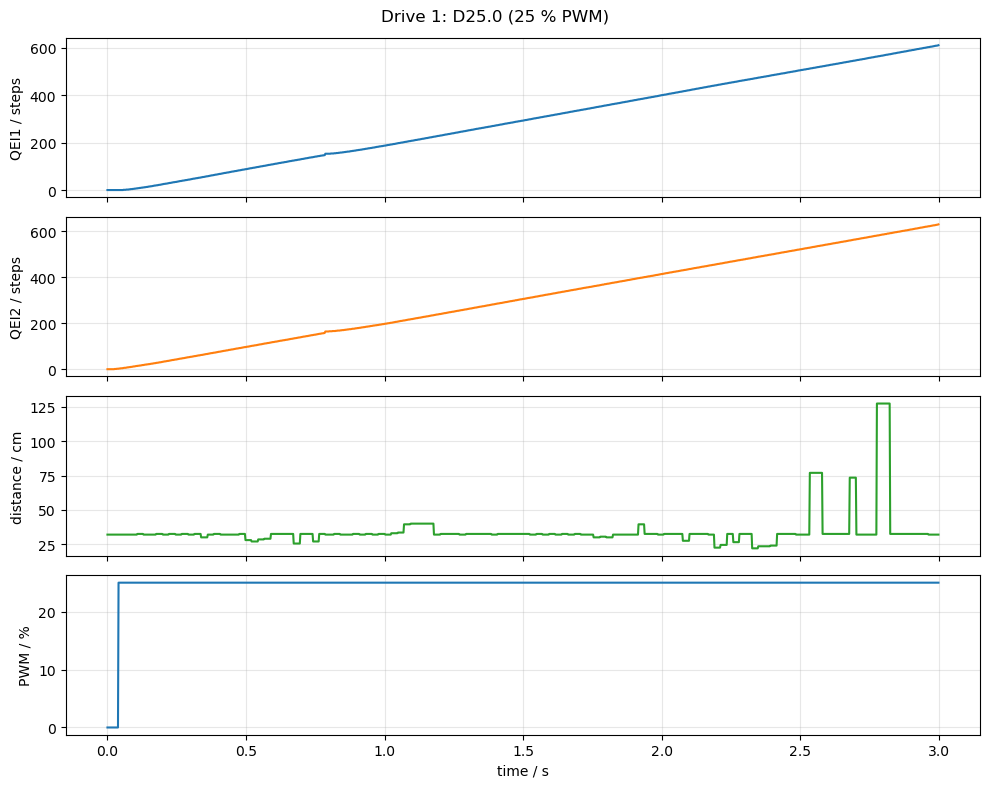

In [2]:
df_d25 = load_log(paths["D25"])
plot_raw(df_d25, "Drive 1: D25.0 (25 % PWM)")
plt.show()

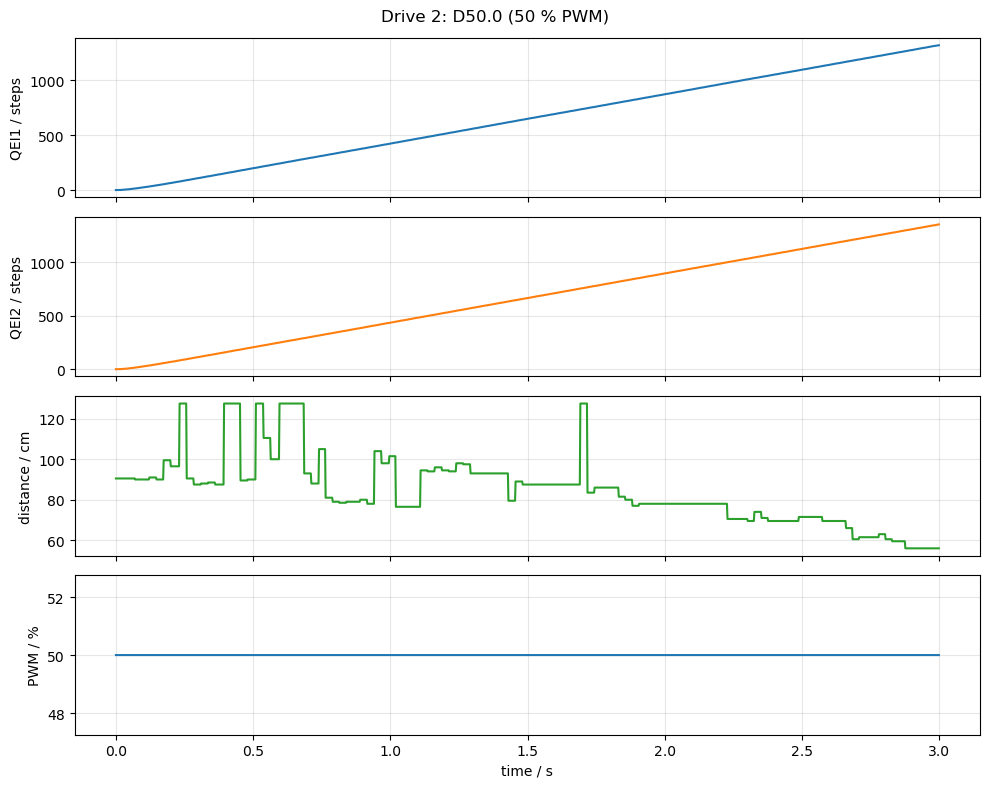

In [3]:
df_d50 = load_log(paths["D50"])
plot_raw(df_d50, "Drive 2: D50.0 (50 % PWM)")
plt.show()

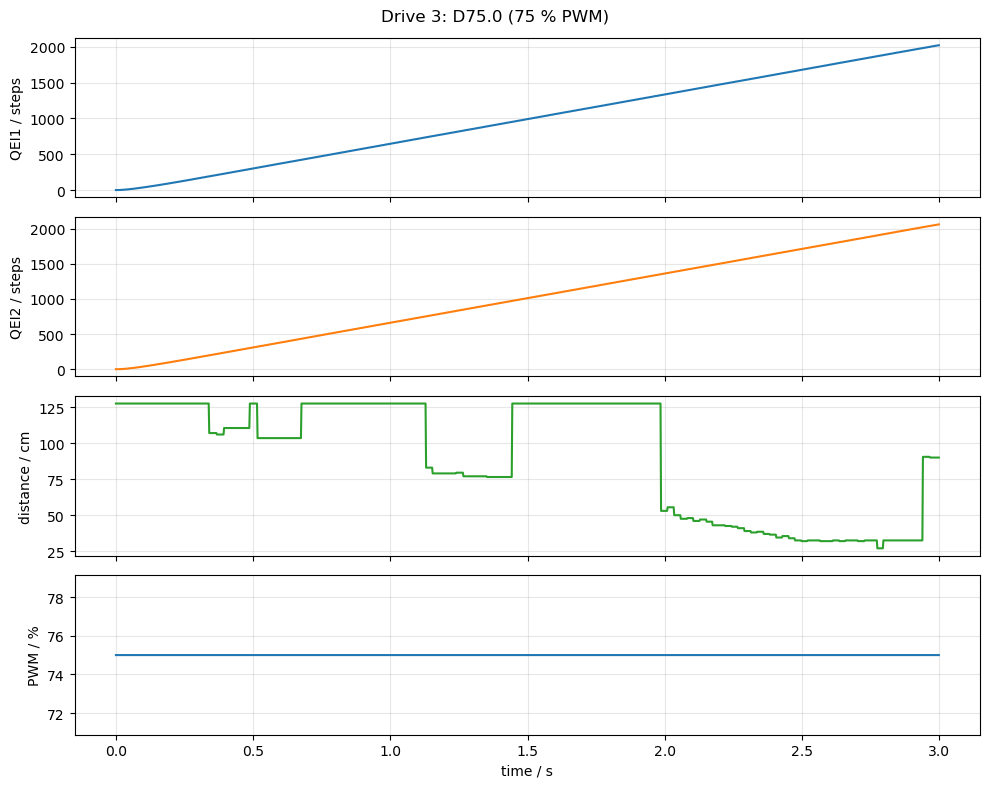

In [4]:
df_d75 = load_log(paths["D75"])
plot_raw(df_d75, "Drive 3: D75.0 (75 % PWM)")
plt.show()

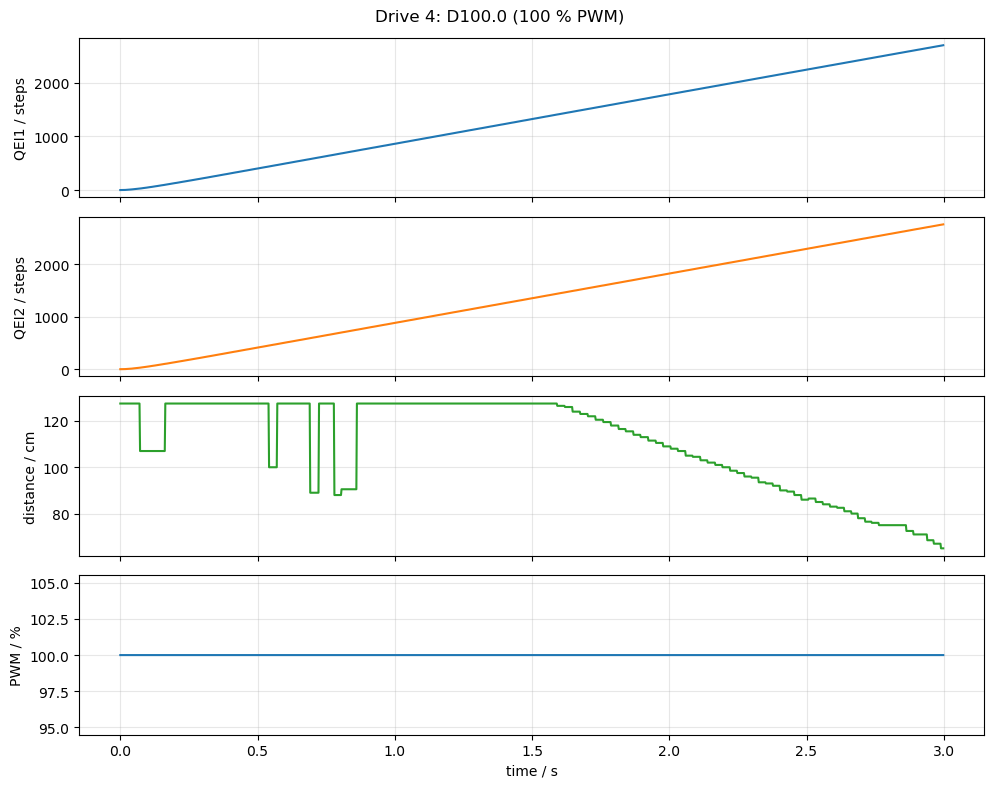

In [5]:
df_d100 = load_log(paths["D100"])
plot_raw(df_d100, "Drive 4: D100.0 (100 % PWM)")
plt.show()

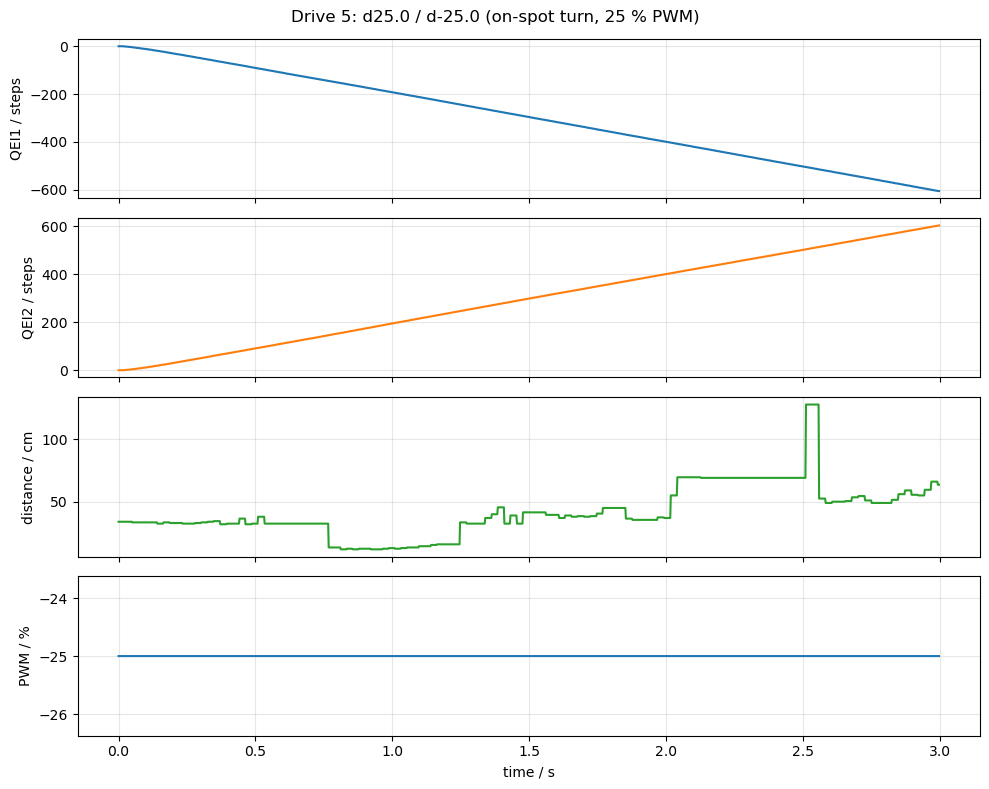

In [6]:
df_pmd25 = load_log(paths["pmD25"])
plot_raw(df_pmd25, "Drive 5: d25.0 / d-25.0 (on-spot turn, 25 % PWM)")
plt.show()

### Motor position QEI: motor 0 vs motor 1, per drive

For each of the four main drives the QEI step counts of motor 0 (`QEI1`) and
motor 1 (`QEI2`) are plotted on the same time axis (top panel) together with
their pointwise difference `QEI2 - QEI1` (bottom panel). The difference makes
the asymmetry between the two drive trains directly visible.

[D25] Mot0/% first reaches 25 % at t = 40 ms
  QEI1/steps: first step at t = 58 ms  (Δt = +18 ms)
  QEI2/steps: first step at t = 26 ms  (Δt = -14 ms)


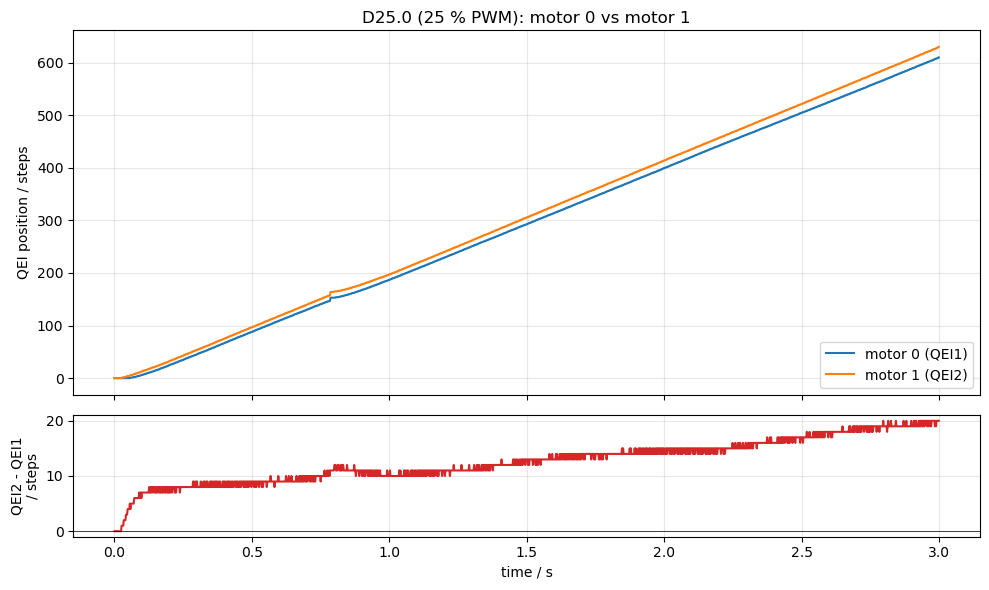

In [7]:
dfs = {key: load_log(paths[key]) for key in ("D25", "D50", "D75", "D100")}

# Save the D25 motor-compare plot to the report figure dir (used as
# fig:drive-25per-deviation in the (e) Observed-behavior subsection).
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print_first_step_delay(dfs["D25"], "D25")
fig, _ = plot_motor_compare(dfs["D25"], "D25.0 (25 % PWM): motor 0 vs motor 1")
fig.savefig(FIG_DIR / "drive-25per-deviation.pdf", bbox_inches="tight")
plt.show()

[D50] Mot0/% first reaches 50 % at t = 0 ms
  QEI1/steps: first step at t = 14 ms  (Δt = +14 ms)
  QEI2/steps: first step at t = 14 ms  (Δt = +14 ms)


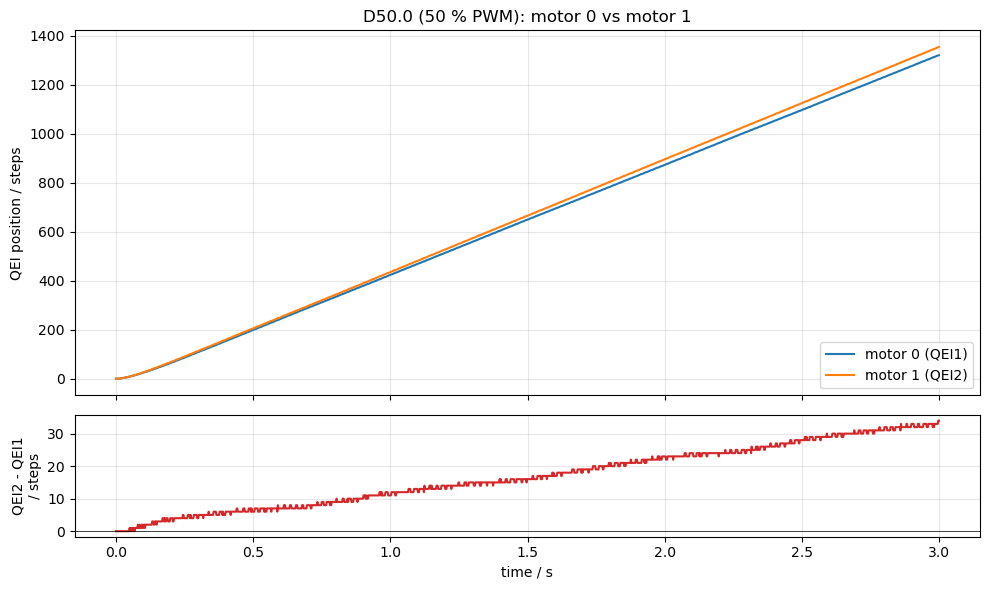

In [8]:
print_first_step_delay(dfs["D50"], "D50")
plot_motor_compare(dfs["D50"], "D50.0 (50 % PWM): motor 0 vs motor 1")
plt.show()

[D75] Mot0/% first reaches 75 % at t = 0 ms
  QEI1/steps: first step at t = 12 ms  (Δt = +12 ms)
  QEI2/steps: first step at t = 14 ms  (Δt = +14 ms)


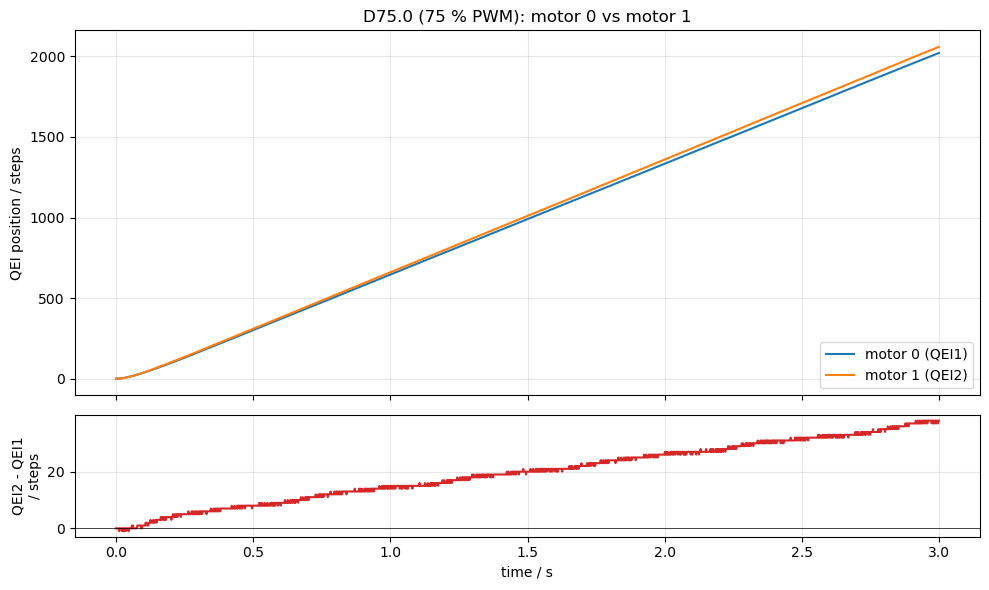

In [9]:
print_first_step_delay(dfs["D75"], "D75")
plot_motor_compare(dfs["D75"], "D75.0 (75 % PWM): motor 0 vs motor 1")
plt.show()

[D100] Mot0/% first reaches 100 % at t = 0 ms
  QEI1/steps: first step at t = 10 ms  (Δt = +10 ms)
  QEI2/steps: first step at t = 12 ms  (Δt = +12 ms)


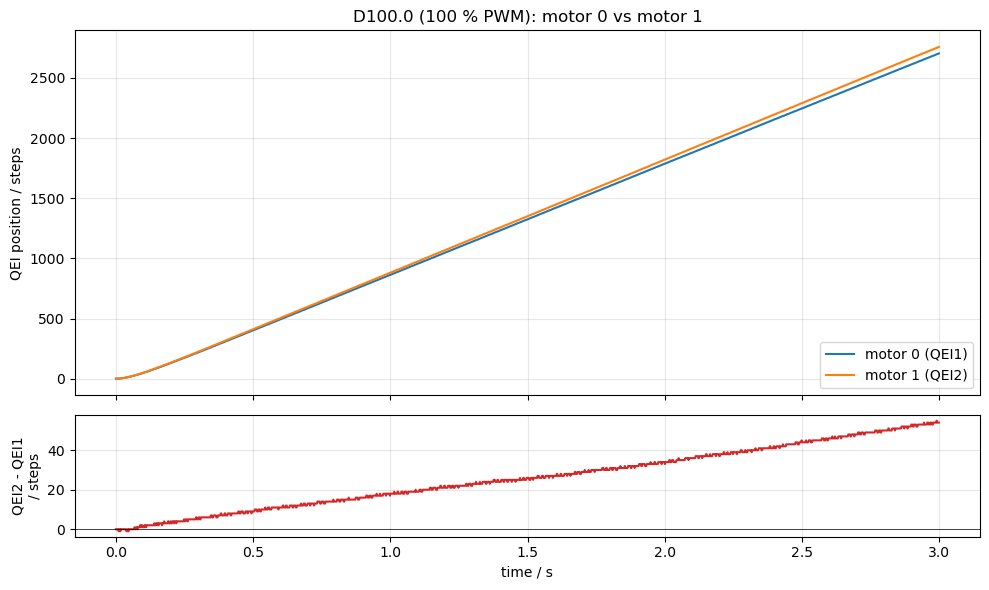

In [10]:
print_first_step_delay(dfs["D100"], "D100")
plot_motor_compare(dfs["D100"], "D100.0 (100 % PWM): motor 0 vs motor 1")
plt.show()

### Angular velocity (smoothed first derivative of QEI position)

For each main drive condition the angular velocities of motor 0 (`dQEI1/dt`)
and motor 1 (`dQEI2/dt`) are plotted in a single figure. The derivative is a
**Savitzky–Golay smoothed derivative**: a cubic polynomial is fitted in a
centered sliding window of 41 samples (≈82 ms at 500 Hz) and its analytic
derivative is taken at each sample. This denoises both the integer
quantization of the encoder and the differentiation noise in one pass,
without significantly distorting the transient response. Units are QEI
counts per second (steps/s); conversion to rad/s requires the encoder's
counts-per-revolution which is not part of the recording.

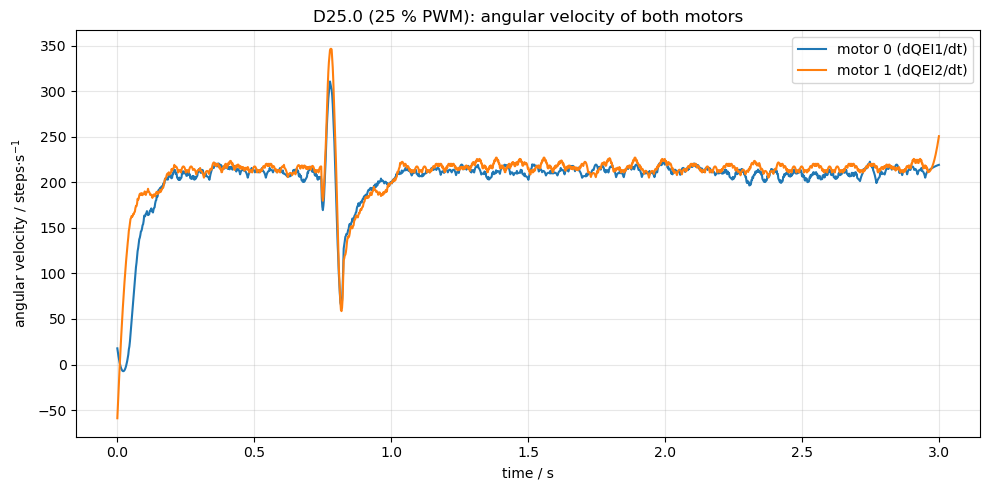

In [11]:
plot_velocity(dfs["D25"], "D25.0 (25 % PWM): angular velocity of both motors")
plt.show()

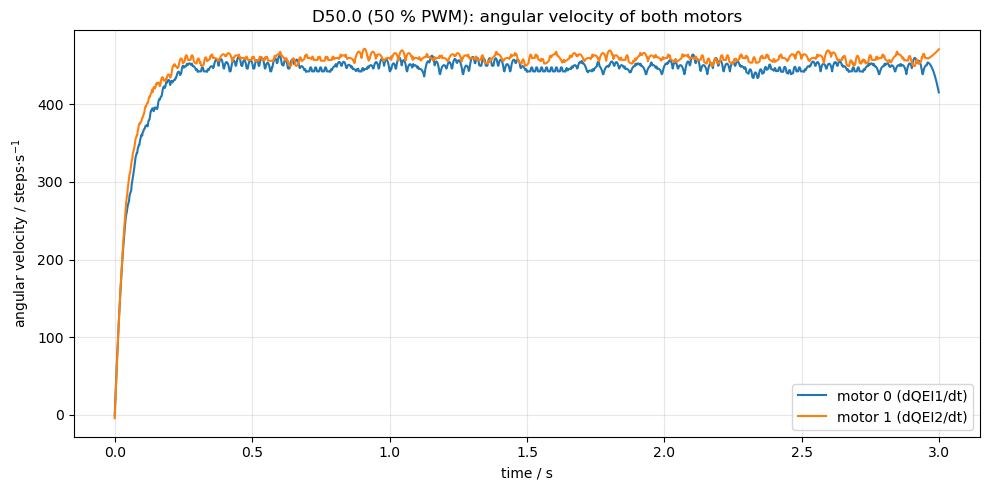

In [12]:
plot_velocity(dfs["D50"], "D50.0 (50 % PWM): angular velocity of both motors")
plt.show()

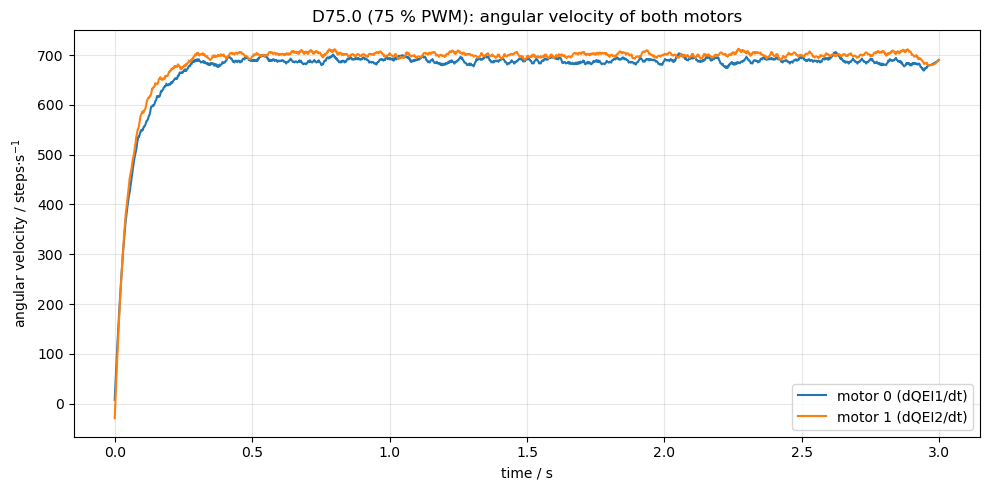

In [13]:
plot_velocity(dfs["D75"], "D75.0 (75 % PWM): angular velocity of both motors")
plt.show()

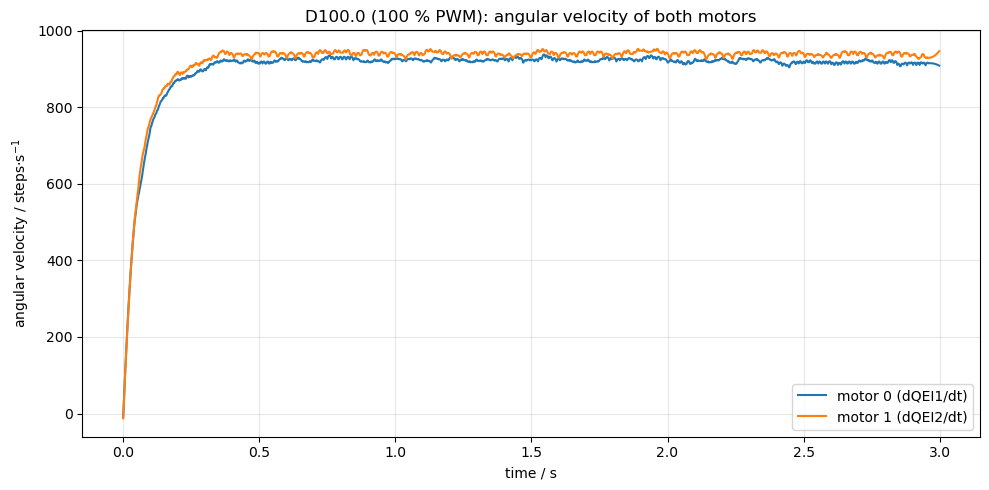

In [14]:
plot_velocity(dfs["D100"], "D100.0 (100 % PWM): angular velocity of both motors")
plt.show()

### second derivative of position plotted as angular acceleration of motors over time (one plot per drive)

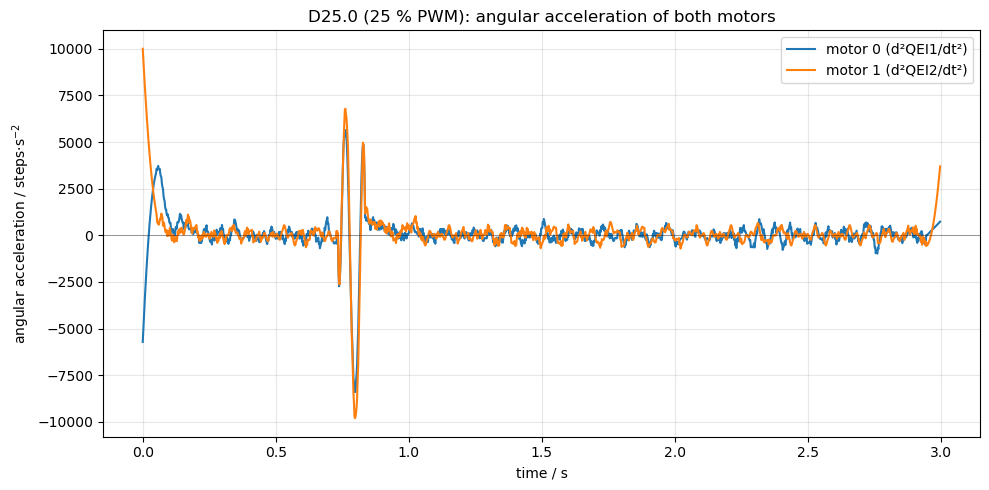

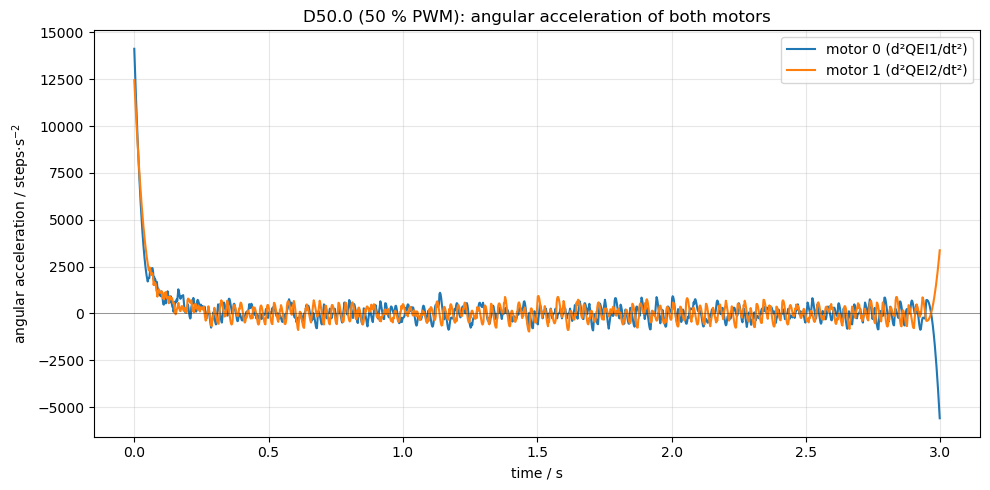

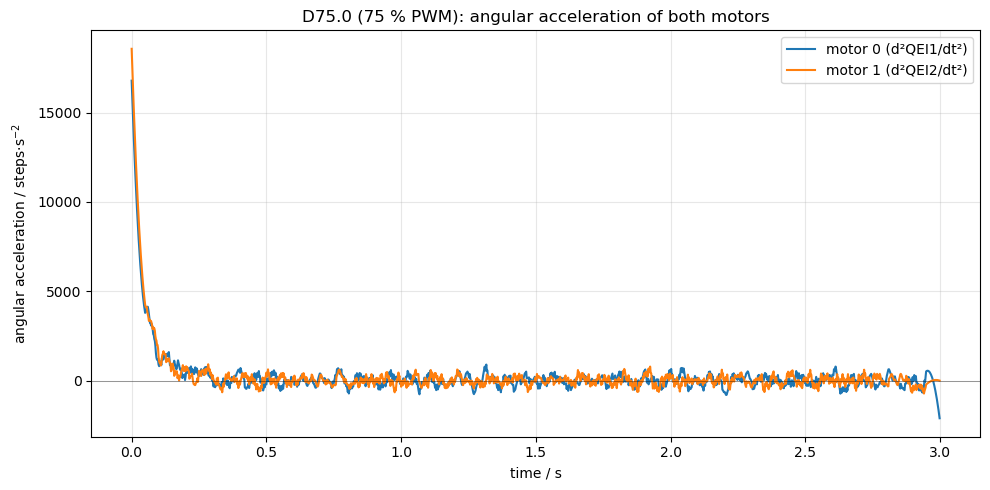

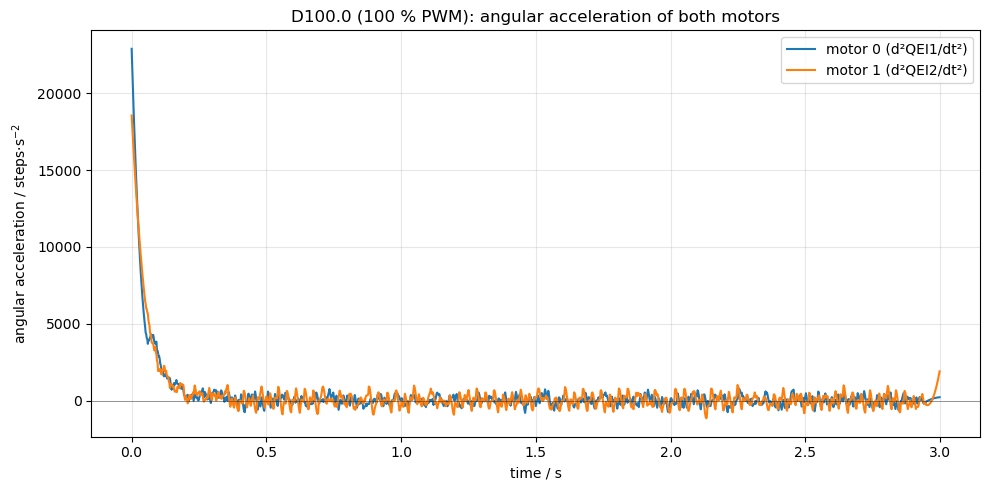

In [15]:
# Angular acceleration  α = d²θ/dt²  for each main duty cycle.
# Savitzky–Golay second derivative, window 51 samples (≈102 ms), polyorder 4.
for key, label in [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]:
    plot_acceleration(dfs[key], f"{key}.0 ({label} PWM): angular acceleration of both motors")
    plt.show()

### third derivative of position plotted as motor jerk over time (one plot per drive)

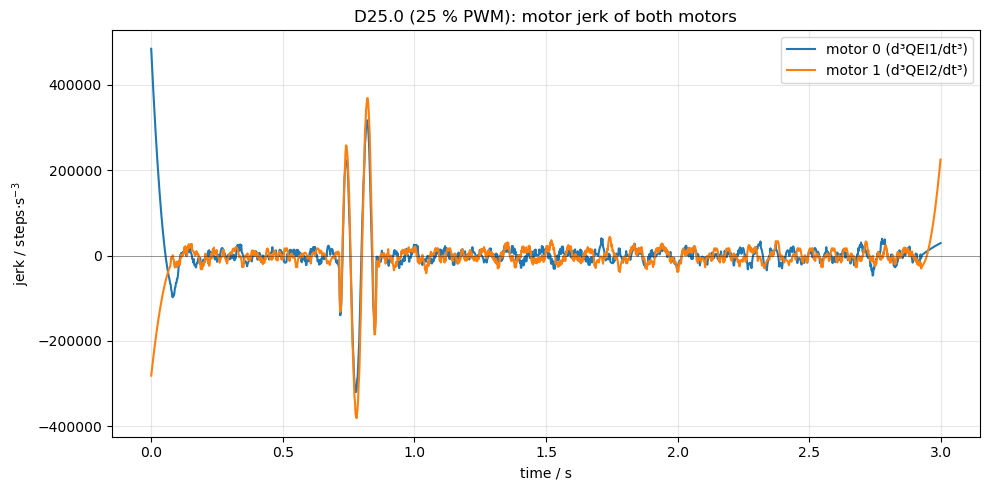

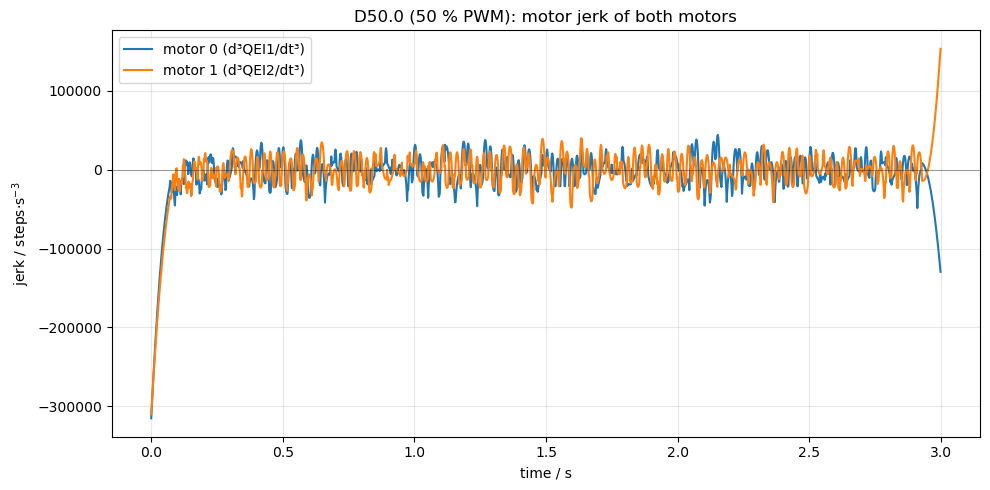

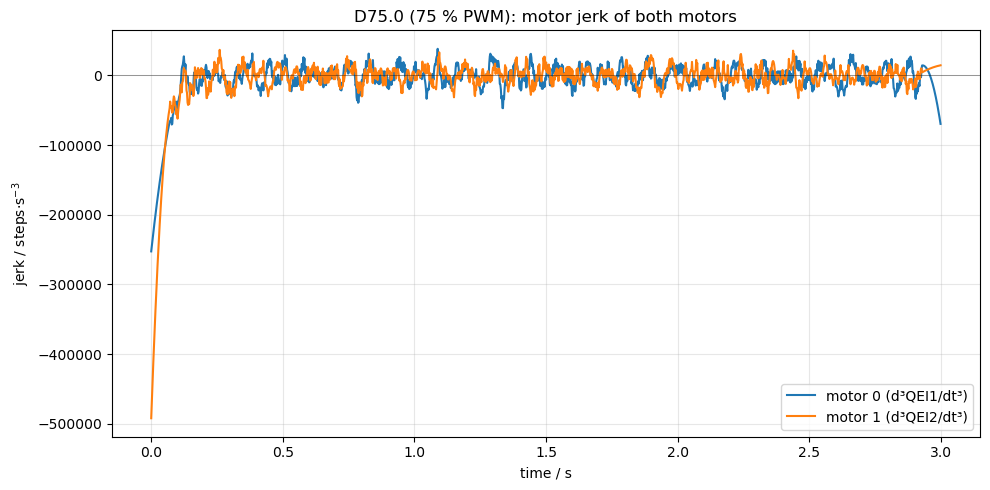

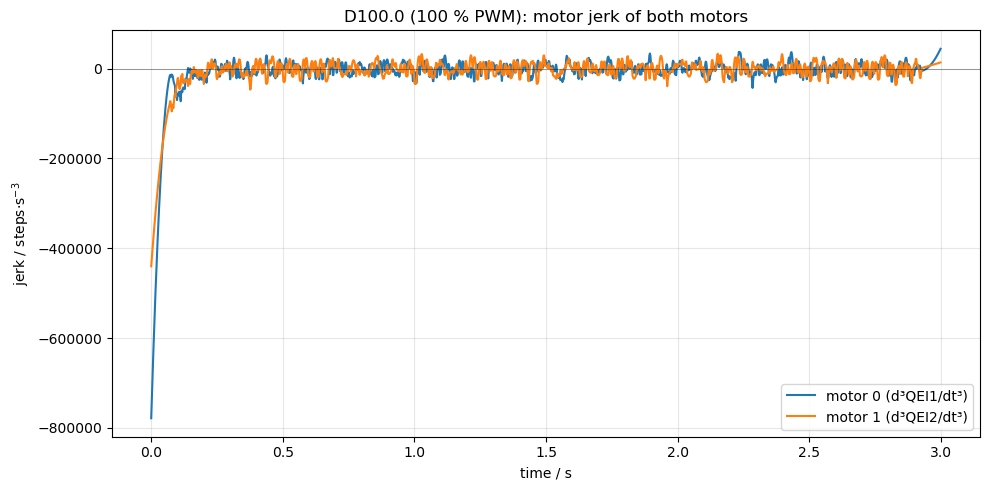

In [16]:
# Motor jerk  j = d³θ/dt³  for each main duty cycle.
# Savitzky–Golay third derivative, window 71 samples (≈142 ms), polyorder 5.
for key, label in [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]:
    plot_jerk(dfs[key], f"{key}.0 ({label} PWM): motor jerk of both motors")
    plt.show()

### first integral of speed plotted as absement of motors over time (one plot per drive)

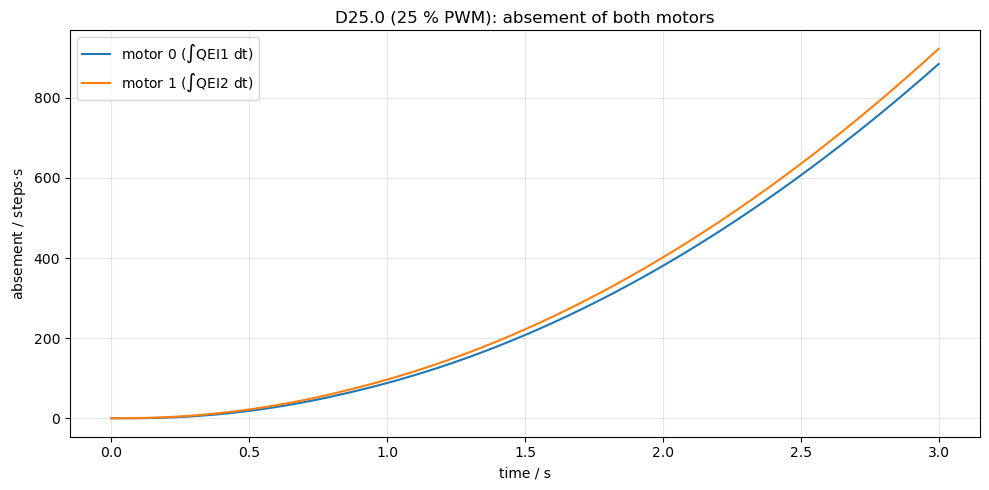

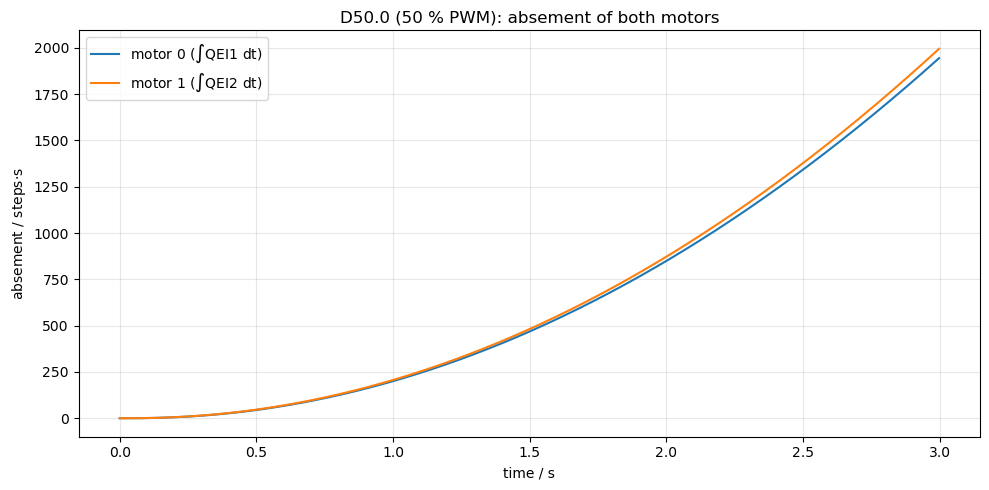

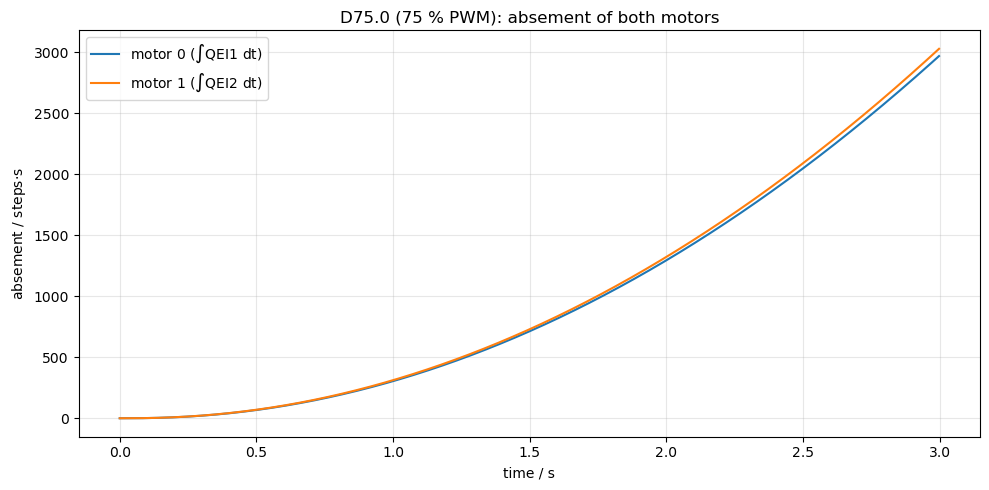

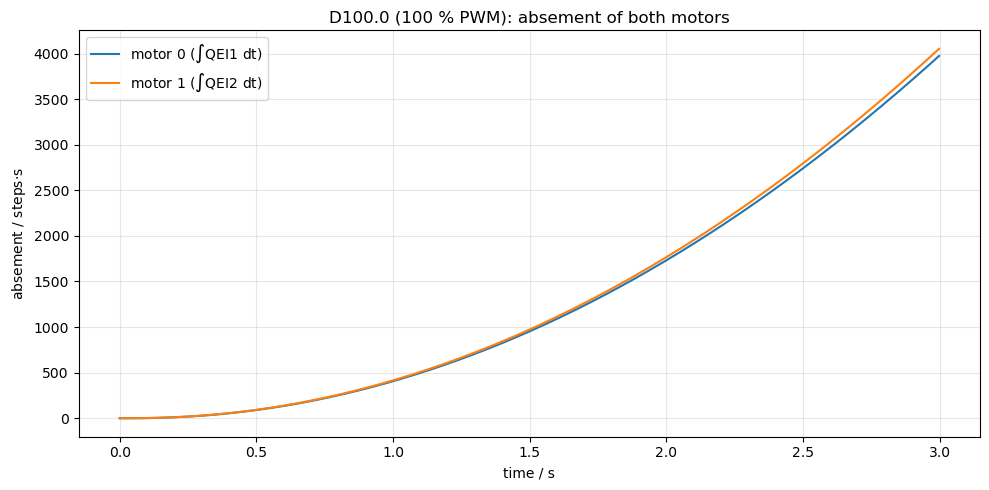

In [17]:
# Absement  A(t) = ∫₀ᵗ θ(τ) dτ  for each main duty cycle.
# Trapezoidal cumulative integral of the raw QEI position. Units: steps·s.
# Note: header text says "first integral of speed" — strictly that is just position
# again; absement is the first integral of *position*, which is what is plotted.
for key, label in [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]:
    plot_absement(dfs[key], f"{key}.0 ({label} PWM): absement of both motors")
    plt.show()

### plot of all derivatives and integrals together for one drive condition (for now just 50% drive) to show the relationship between the different analysed variables (one plot total)

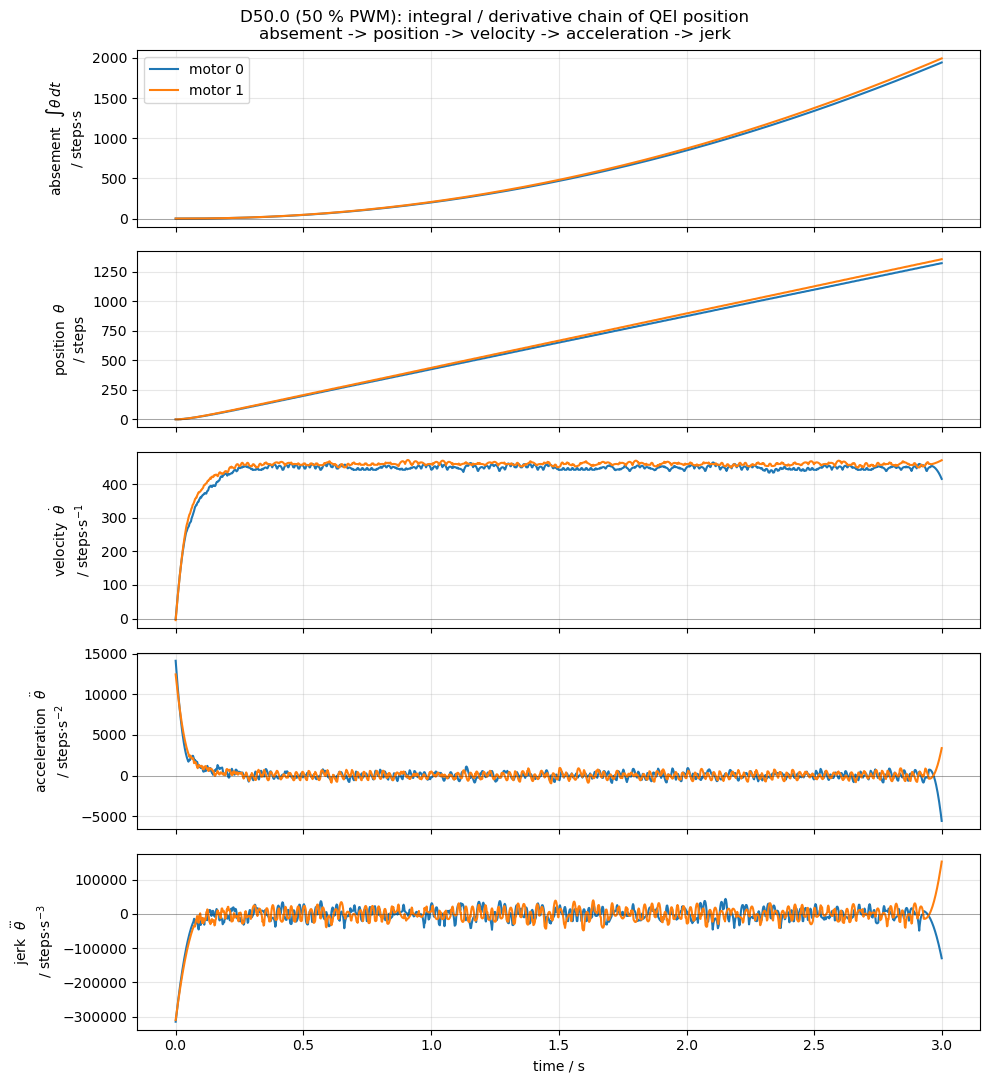

In [18]:
# Combined integral/derivative chain for D50 (50 % PWM): five stacked panels
# sharing the time axis, top to bottom in order of differentiation:
#   absement -> position -> velocity -> acceleration -> jerk
# Both motors per panel (motor 0 blue, motor 1 orange).
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = dfs["D50"]
t = df["t/s"]
q1, q2 = df["QEI1/steps"], df["QEI2/steps"]

A1, A2 = absement(q1, t),               absement(q2, t)
v1, v2 = angular_velocity(q1, t),       angular_velocity(q2, t)
a1, a2 = angular_acceleration(q1, t),   angular_acceleration(q2, t)
j1, j2 = angular_jerk(q1, t),           angular_jerk(q2, t)

panels = [
    (A1, A2, r"absement  $\int\theta\,dt$" + "\n" + r"/ steps$\cdot$s"),
    (q1, q2, r"position  $\theta$"          + "\n" + r"/ steps"),
    (v1, v2, r"velocity  $\dot\theta$"      + "\n" + r"/ steps$\cdot$s$^{-1}$"),
    (a1, a2, r"acceleration  $\ddot\theta$" + "\n" + r"/ steps$\cdot$s$^{-2}$"),
    (j1, j2, r"jerk  $\dddot\theta$"        + "\n" + r"/ steps$\cdot$s$^{-3}$"),
]

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 11), sharex=True)
for i, (ax, (s1, s2, ylabel)) in enumerate(zip(axes, panels)):
    ax.plot(t, s1, color="tab:blue",   label="motor 0" if i == 0 else None)
    ax.plot(t, s2, color="tab:orange", label="motor 1" if i == 0 else None)
    ax.axhline(0, color="black", linewidth=0.4, alpha=0.5)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
axes[0].legend(loc="upper left")
axes[-1].set_xlabel("time / s")
fig.suptitle("D50.0 (50 % PWM): integral / derivative chain of QEI position\n"
             "absement -> position -> velocity -> acceleration -> jerk")
fig.tight_layout()

fig.savefig(FIG_DIR / "d50-integral-derivative-chain.pdf", bbox_inches="tight")
plt.show()

### Differential-drive kinematics — distance, heading and trajectory from QEI

(Extra appendix calculation — not part of task (f).)

Using the wheel encoder counts the body-frame motion of the robot can be
reconstructed under the **classic differential-drive / no-slip assumption**. The pipeline below executes this step by step:

| step | quantity | formula |
|------|----------|---------|
| 1 | wheel angles | $\theta = (\text{steps}/\mathrm{CPR}) \cdot 2\pi$ |
| 1 | per-wheel arc length | $s_L = r\,\theta_L$, $\quad s_R = r\,\theta_R$ |
| 2 | body forward path | $s = (s_R + s_L)/2$ |
| 2 | body heading change | $\Delta\varphi = (s_R - s_L)/L$ |
| 3 | body forward velocity | $v = \dot s$ |
| 3 | body yaw rate | $\omega = \dot\varphi$ |
| 4 | world-frame pose | midpoint-heading integration of $(\Delta s, \Delta\varphi)$ |

Convention used here: motor 0 (`QEI1`) is the **left** wheel, motor 1
(`QEI2`) is the **right** wheel, positive $\varphi$ is counterclockwise
(viewed from above). The robot parameters are estimates for a typical EV3
educational chassis; if you have measurements for your RetBot adjust the
`WHEEL_RADIUS_M`, `WHEEL_SEPARATION_M`, `CPR` constants below and re-run.

In [19]:
# ----- Setup: robot parameters and kinematics helper ----------------------
# Estimates for a typical EV3 RetBot — replace with measured values if known.
WHEEL_RADIUS_M     = 0.028   # 56 mm wheel diameter → r = 28 mm
WHEEL_SEPARATION_M = 0.120   # L = 12 cm centre-to-centre wheel separation
CPR                = 360     # encoder counts per wheel revolution (after gearbox)

# Convention: motor 0 (QEI1) = LEFT wheel,  motor 1 (QEI2) = RIGHT wheel
LEFT_COL  = "QEI1/steps"
RIGHT_COL = "QEI2/steps"


def wheel_angle_rad(qei_steps, cpr=CPR):
    """Encoder counts → wheel angle in radians (at the wheel, after gearbox)."""
    return (qei_steps / cpr) * 2 * np.pi


def differential_drive(df, r=WHEEL_RADIUS_M, L=WHEEL_SEPARATION_M, cpr=CPR):
    """Classic differential-drive kinematics from a Serial.ICE log.

    Returns a DataFrame containing wheel angles + arc lengths, body-frame
    path / heading / velocities / acceleration, and a world-frame pose
    (x, y, φ) integrated with the midpoint-heading rule.
    """
    out = df[["t/s"]].copy()

    # Step 1 — wheel angles and per-wheel arc length
    out["theta_L"] = wheel_angle_rad(df[LEFT_COL])
    out["theta_R"] = wheel_angle_rad(df[RIGHT_COL])
    out["s_L"] = r * out["theta_L"]                       # m
    out["s_R"] = r * out["theta_R"]                       # m

    # Step 2 — body forward path length and heading
    out["s"]   = 0.5 * (out["s_R"] + out["s_L"])          # m
    out["phi"] = (out["s_R"] - out["s_L"]) / L            # rad (cumulative)

    # Step 3 — body velocities and acceleration (Savitzky–Golay derivatives)
    out["v"]     = angular_velocity(out["s"],   out["t/s"])   # m·s⁻¹
    out["omega"] = angular_velocity(out["phi"], out["t/s"])   # rad·s⁻¹
    out["a"]     = angular_velocity(out["v"],   out["t/s"])   # m·s⁻²

    # Step 4 — world-frame pose integrated with the midpoint-heading rule
    phi = out["phi"].values
    ds  = np.diff(out["s"].values)
    h_mid = 0.5 * (phi[1:] + phi[:-1])
    dx = ds * np.cos(h_mid)
    dy = ds * np.sin(h_mid)
    out["x"]         = np.concatenate(([0.0], np.cumsum(dx)))
    out["y"]         = np.concatenate(([0.0], np.cumsum(dy)))
    out["phi_world"] = phi   # equivalent to cumulative Δφ since phi[0] = 0

    return out


# Compute kinematics for the four main drives plus the on-spot turn
all_drives = {**dfs, "pmD25": load_log(paths["pmD25"])}
kins = {key: differential_drive(df) for key, df in all_drives.items()}

# Local copies of styling/output dirs so this cell is self-contained
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)
DRIVES = [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]
DRIVE_COLORS = plt.cm.viridis([0.15, 0.4, 0.65, 0.9])

print(f"Robot parameters: r = {WHEEL_RADIUS_M*1000:.1f} mm,  "
      f"L = {WHEEL_SEPARATION_M*1000:.1f} mm,  CPR = {CPR}")
print(f"Convention: motor 0 (QEI1) = LEFT wheel,  motor 1 (QEI2) = RIGHT wheel")
print()
print(f"{'drive':6s}  s_L final (m)  s_R final (m)   path s (m)   heading Δφ (deg)")
for k in ("D25", "D50", "D75", "D100", "pmD25"):
    kk = kins[k]
    print(f"{k:6s}  {kk['s_L'].iloc[-1]:>11.3f}    {kk['s_R'].iloc[-1]:>11.3f}    "
          f"{kk['s'].iloc[-1]:>9.3f}    {np.degrees(kk['phi'].iloc[-1]):>10.1f}")

Robot parameters: r = 28.0 mm,  L = 120.0 mm,  CPR = 360
Convention: motor 0 (QEI1) = LEFT wheel,  motor 1 (QEI2) = RIGHT wheel

drive   s_L final (m)  s_R final (m)   path s (m)   heading Δφ (deg)
D25           0.298          0.308        0.303           4.7
D50           0.645          0.662        0.653           7.9
D75           0.988          1.006        0.997           8.9
D100          1.321          1.348        1.335          12.6
pmD25        -0.296          0.295       -0.000         281.9


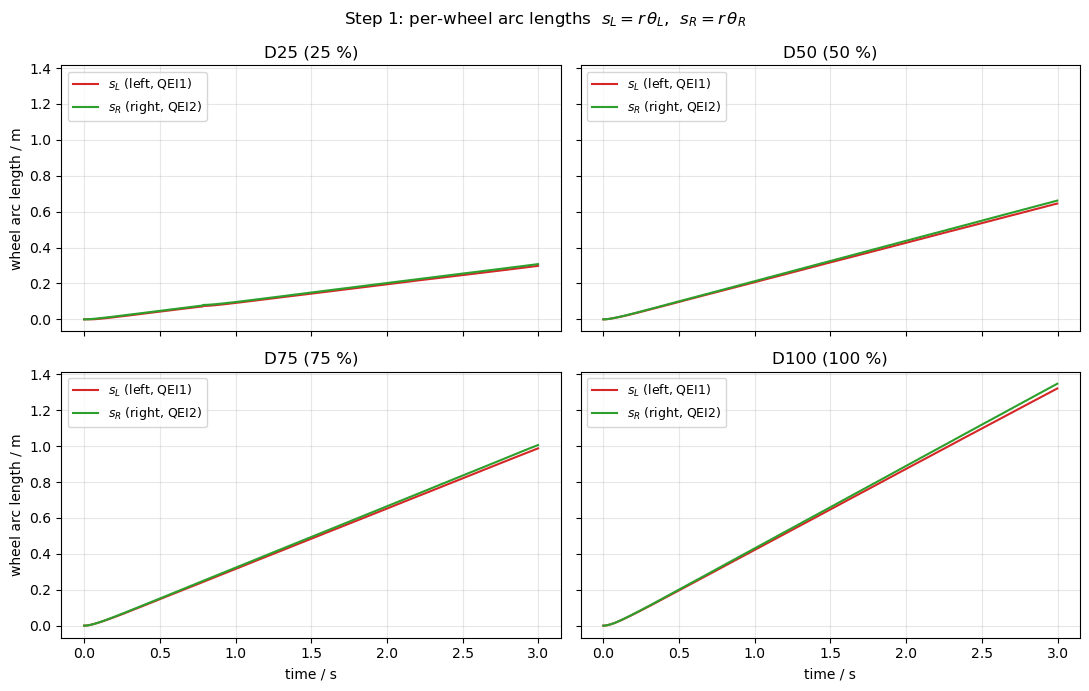

In [20]:
# Step 1 — per-wheel arc length s_L (left) vs s_R (right) for each main drive.
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (key, label) in zip(axes.flat, DRIVES):
    k = kins[key]
    ax.plot(k["t/s"], k["s_L"], color="tab:red",   label=r"$s_L$ (left, QEI1)")
    ax.plot(k["t/s"], k["s_R"], color="tab:green", label=r"$s_R$ (right, QEI2)")
    ax.set_title(f"{key} ({label})")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=9)
for ax in axes[-1, :]:
    ax.set_xlabel("time / s")
for ax in axes[:, 0]:
    ax.set_ylabel("wheel arc length / m")
fig.suptitle(r"Step 1: per-wheel arc lengths  $s_L = r\,\theta_L$,  $s_R = r\,\theta_R$")
fig.tight_layout()
plt.show()

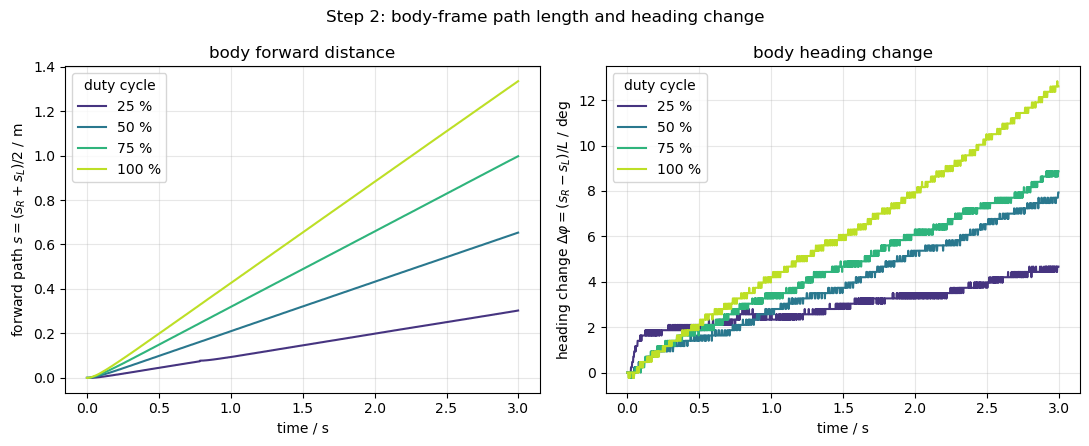

In [21]:
# Step 2 — body forward path length s and heading change Δφ.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    k = kins[key]
    axes[0].plot(k["t/s"], k["s"],                color=color, label=label)
    axes[1].plot(k["t/s"], np.degrees(k["phi"]),  color=color, label=label)
axes[0].set_xlabel("time / s")
axes[0].set_ylabel(r"forward path $s = (s_R + s_L)/2$ / m")
axes[0].set_title("body forward distance")
axes[1].set_xlabel("time / s")
axes[1].set_ylabel(r"heading change $\Delta\varphi = (s_R - s_L)/L$ / deg")
axes[1].set_title("body heading change")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="best")
fig.suptitle("Step 2: body-frame path length and heading change")
fig.tight_layout()

fig.savefig(FIG_DIR / "differential-drive-distance-heading.pdf", bbox_inches="tight")
plt.show()

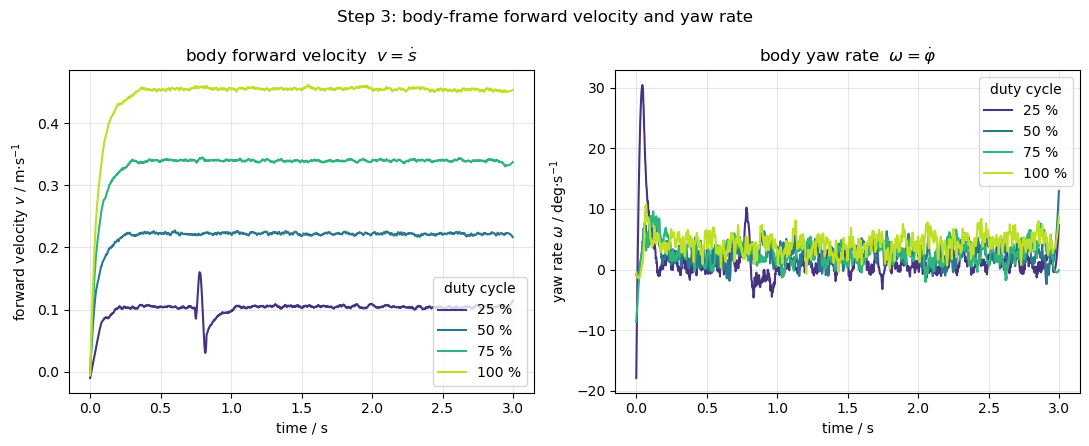

In [22]:
# Step 3 — body forward velocity v and yaw rate ω (smoothed time derivatives).
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    k = kins[key]
    axes[0].plot(k["t/s"], k["v"],                    color=color, label=label)
    axes[1].plot(k["t/s"], np.degrees(k["omega"]),    color=color, label=label)
axes[0].set_xlabel("time / s")
axes[0].set_ylabel(r"forward velocity $v$ / m$\cdot$s$^{-1}$")
axes[0].set_title(r"body forward velocity  $v = \dot s$")
axes[1].set_xlabel("time / s")
axes[1].set_ylabel(r"yaw rate $\omega$ / deg$\cdot$s$^{-1}$")
axes[1].set_title(r"body yaw rate  $\omega = \dot\varphi$")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="best")
fig.suptitle("Step 3: body-frame forward velocity and yaw rate")
fig.tight_layout()
plt.show()

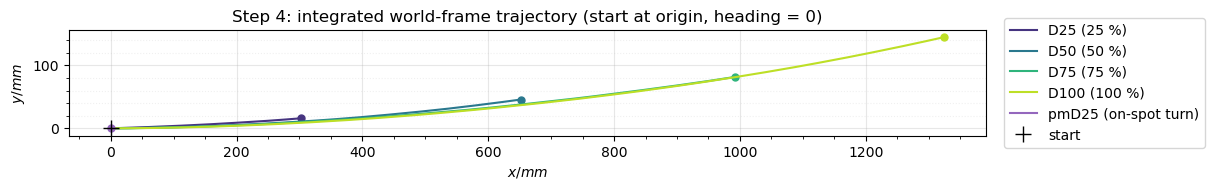

In [23]:
# Step 4 — world-frame trajectory (x, y) integrated from (s, φ).
MM = 1000.0

fig, ax = plt.subplots(figsize=(15, 20))
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    k = kins[key]
    x_mm = k["x"] * MM
    y_mm = k["y"] * MM
    ax.plot(x_mm, y_mm, color=color, linewidth=1.5, label=f"{key} ({label})")
    ax.plot(x_mm.iloc[-1], y_mm.iloc[-1], "o", color=color, markersize=5)

# Overlay the on-spot turn for contrast (s ≈ 0, large Δφ)
k = kins["pmD25"]
x_mm = k["x"] * MM
y_mm = k["y"] * MM
ax.plot(x_mm, y_mm, color="tab:purple", linewidth=1.5, label="pmD25 (on-spot turn)")
ax.plot(x_mm.iloc[-1], y_mm.iloc[-1], "o", color="tab:purple", markersize=5)

ax.plot(0, 0, "k+", markersize=12, label="start")
ax.set_xlabel("$x / mm$")
ax.set_ylabel("$y / mm$")
ax.set_aspect("equal", "box")
ax.minorticks_on()
ax.grid(True, which="major", axis="both", alpha=0.3)
ax.grid(True, which="minor", axis="y", alpha=0.18, linestyle=":")
ax.margins(y=0.08)
ax.set_title("Step 4: integrated world-frame trajectory (start at origin, heading = 0)")

# Keep legend fully outside the axes on the right.
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), borderaxespad=0.0)
fig.tight_layout(rect=[0.0, 0.0, 0.82, 1.0])

fig.savefig(FIG_DIR / "differential-drive-trajectory.pdf", bbox_inches="tight")
plt.show()

### Plots for report 
1) QEI position of motor 0 and motor 1 on the same time axis, together with the difference between the motor--motor1-speed pair colored, in one figure for all four main drive conditions (motor 0 should always be a dashed line and motor 1 should always be a solid line, with the same color for the same drive condition, and the difference(area) should colored in the same color but with higher opacity)

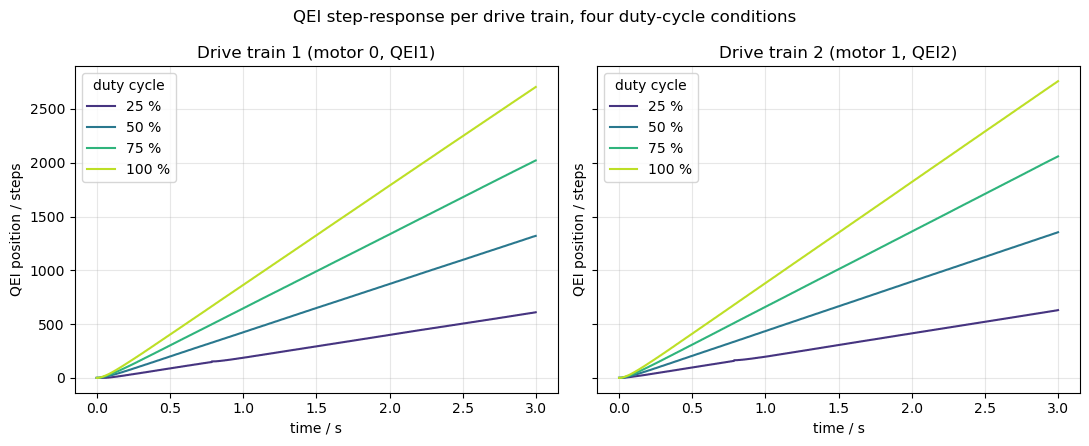

In [24]:
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DRIVES = [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]
DRIVE_COLORS = plt.cm.viridis([0.15, 0.4, 0.65, 0.9])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    axes[0].plot(dfs[key]["t/s"], dfs[key]["QEI1/steps"], label=label, color=color)
    axes[1].plot(dfs[key]["t/s"], dfs[key]["QEI2/steps"], label=label, color=color)
axes[0].set_title("Drive train 1 (motor 0, QEI1)")
axes[1].set_title("Drive train 2 (motor 1, QEI2)")
for ax in axes:
    ax.set_xlabel("time / s")
    ax.set_ylabel("QEI position / steps")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="upper left")
fig.suptitle("QEI step-response per drive train, four duty-cycle conditions")
fig.tight_layout()

fig.savefig(FIG_DIR / "drive-position-comparison.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-position-comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### Plots for report 
1.2) QEI position of motor 0 and motor 1 on the same plot and time axis, together with the difference between the motor--motor1-speed pair colored, in one figure for all four main drive conditions (motor 0 should always be a dashed line and motor 1 should always be a solid line, with the same color for the same drive condition, and the difference(area) should colored in the same color but with higher opacity)

### Plots for report
2) angular velocity of motor 0 and motor 1 

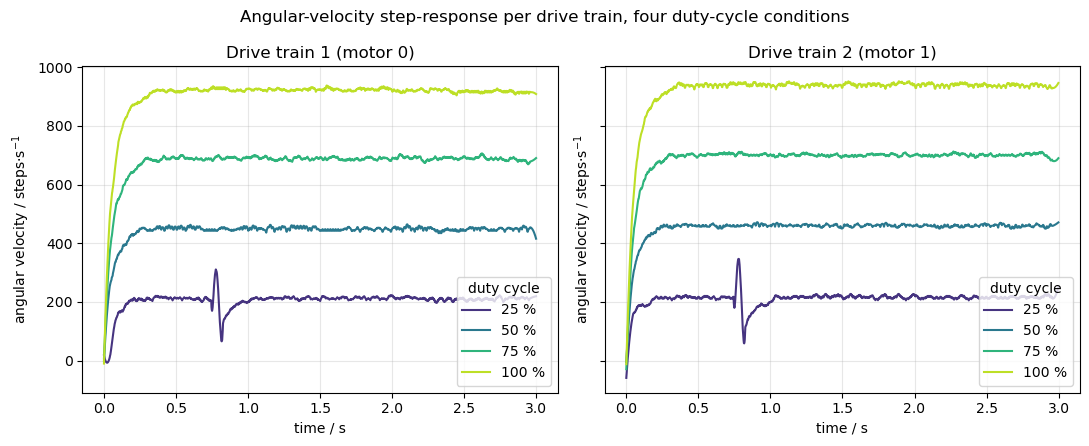

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    df = dfs[key]
    axes[0].plot(df["t/s"], angular_velocity(df["QEI1/steps"], df["t/s"]),
                 label=label, color=color)
    axes[1].plot(df["t/s"], angular_velocity(df["QEI2/steps"], df["t/s"]),
                 label=label, color=color)
axes[0].set_title("Drive train 1 (motor 0)")
axes[1].set_title("Drive train 2 (motor 1)")
for ax in axes:
    ax.set_xlabel("time / s")
    ax.set_ylabel(r"angular velocity / steps$\cdot$s$^{-1}$")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="lower right")
fig.suptitle("Angular-velocity step-response per drive train, four duty-cycle conditions")
fig.tight_layout()

fig.savefig(FIG_DIR / "drive-velocity-comparison.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-velocity-comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### Plots for report
3) QEI moving up and down plot from trial 5 (opposite direction) and showing that QEI output shows the motor spinning in the opposite direction if motor moves in the opposite direction\\
and the Angular-velocity of both motors 
motor0 d25.0 and motor1 d-25.0
all in one plot with a  `Left red`, `right green`. and the derivative in a lighter color of the same color as the position plot. 


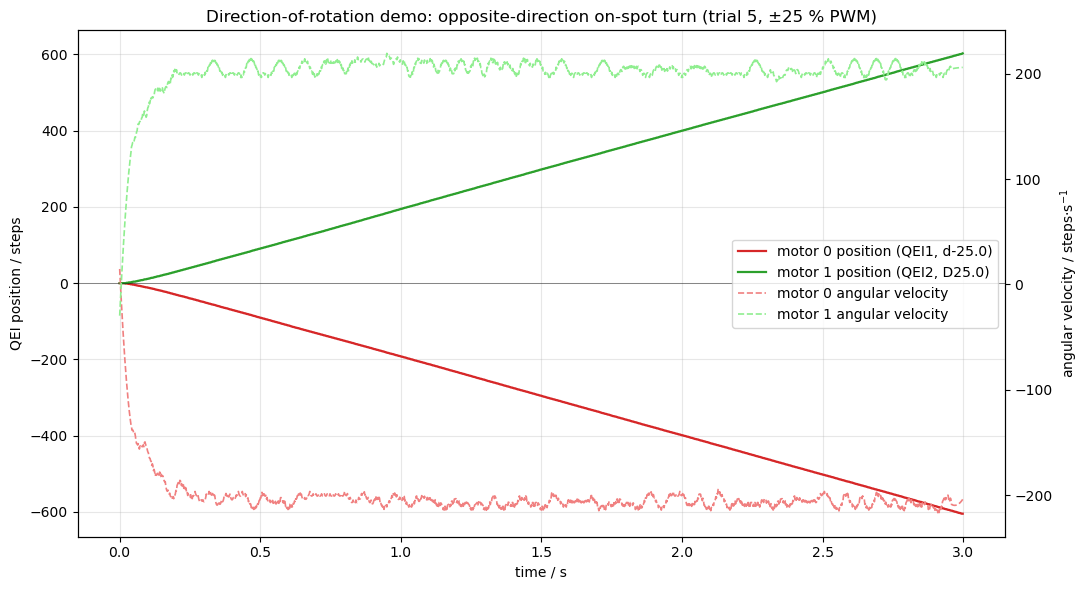

In [26]:
df_pmd25 = load_log(paths["pmD25"])
t = df_pmd25["t/s"]
q1 = df_pmd25["QEI1/steps"]   # motor 0 — recorded Mot0=-25 %, QEI1 decrements
q2 = df_pmd25["QEI2/steps"]   # motor 1 — opposite direction, QEI2 increments
o1 = angular_velocity(q1, t)
o2 = angular_velocity(q2, t)

color_m0    = "tab:red"        # motor 0 = "left"  → red  (port convention)
color_m0_v  = "lightcoral"     # lighter shade for the derivative
color_m1    = "tab:green"      # motor 1 = "right" → green (starboard convention)
color_m1_v  = "lightgreen"

fig, ax_pos = plt.subplots(figsize=(11, 6))
ax_vel = ax_pos.twinx()

l1, = ax_pos.plot(t, q1, color=color_m0, linewidth=1.6,
                  label="motor 0 position (QEI1, d-25.0)")
l2, = ax_pos.plot(t, q2, color=color_m1, linewidth=1.6,
                  label="motor 1 position (QEI2, D25.0)")

l3, = ax_vel.plot(t, o1, color=color_m0_v, linewidth=1.2, linestyle="--",
                  label="motor 0 angular velocity")
l4, = ax_vel.plot(t, o2, color=color_m1_v, linewidth=1.2, linestyle="--",
                  label="motor 1 angular velocity")

ax_pos.axhline(0, color="black", linewidth=0.5, alpha=0.6)
ax_pos.set_xlabel("time / s")
ax_pos.set_ylabel("QEI position / steps")
ax_vel.set_ylabel(r"angular velocity / steps$\cdot$s$^{-1}$")
ax_pos.grid(True, alpha=0.3)
ax_pos.set_title("Direction-of-rotation demo: opposite-direction on-spot turn (trial 5, ±25 % PWM)")

ax_pos.legend(handles=[l1, l2, l3, l4], loc="center right")

fig.tight_layout()
fig.savefig(FIG_DIR / "qei-direction-of-rotation.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "qei-direction-of-rotation.png", dpi=200, bbox_inches="tight")
plt.show()